In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


In [19]:
# Load the synthetic dataset
csv_path = "synthetic_data.csv"
df = pd.read_csv(csv_path)

print(f"Dataset loaded: {csv_path}")
print(f"Total records: {len(df)}")
print(f"Unique crops: {df['crop'].nunique()}")
print(f"Unique states: {df['state'].nunique()}")
print(f"Unique cities: {df['city'].nunique()}")
print("\nFirst few rows:")
display(df.head())
print("\nDataset Info:")
display(df.info())

Dataset loaded: synthetic_data.csv
Total records: 10000
Unique crops: 20
Unique states: 20
Unique cities: 100

First few rows:


,crop,state,city,best_month,month_name,avg_temp_C,avg_rainfall_mm,suitability_score,soil_type,soil_ph,duration_days
0,Sugarcane,Maharashtra,Nagpur,3,Mar,25.8,39.6,76,Alluvial,7.2,146
1,Coconut,Tamil Nadu,Salem,9,Sep,31.0,105.9,80,Loamy,5.3,89
2,Banana,Goa,Panaji,3,Mar,26.9,2.3,63,Alluvial,7.1,149
3,Coconut,Haryana,Faridabad,4,Apr,33.9,19.6,75,Laterite,5.8,171
4,Rice,Gujarat,Rajkot,6,Jun,28.6,85.8,66,Black,5.5,157



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   crop               10000 non-null  object 
 1   state              10000 non-null  object 
 2   city               10000 non-null  object 
 3   best_month         10000 non-null  int64  
 4   month_name         10000 non-null  object 
 5   avg_temp_C         10000 non-null  float64
 6   avg_rainfall_mm    10000 non-null  float64
 7   suitability_score  10000 non-null  int64  
 8   soil_type          10000 non-null  object 
 9   soil_ph            10000 non-null  float64
 10  duration_days      10000 non-null  int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 859.5+ KB


None

In [20]:
# Create and fit label encoders for categorical features
encoders = {}
encoders['crop'] = LabelEncoder().fit(df['crop'])
encoders['state'] = LabelEncoder().fit(df['state'])
encoders['city'] = LabelEncoder().fit(df['city'])
encoders['month'] = LabelEncoder().fit(df['month_name'])
encoders['crop_label'] = LabelEncoder().fit(df['crop'])

print("Label Encoders Created:")
print(f"✓ Crops: {len(encoders['crop'].classes_)}")
print(f"✓ States: {len(encoders['state'].classes_)}")
print(f"✓ Cities: {len(encoders['city'].classes_)}")


Label Encoders Created:
✓ Crops: 20
✓ States: 20
✓ Cities: 100


In [21]:
# Cell 5: Prepare Data for Model 1 (Predict Month from Crop, State, City)
print("="*80)
print("MODEL 1: Predict Best Month (Given: Crop, State, City)")
print("="*80)

# Features: crop, state, city
X1 = pd.DataFrame({
    "crop": encoders['crop'].transform(df['crop']),
    "state": encoders['state'].transform(df['state']),
    "city": encoders['city'].transform(df['city'])
})

# Target: best_month (1-12)
y1 = df['best_month']

# Train/test split
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=RANDOM_STATE, stratify=y1
)

print(f"Training samples: {len(X1_train)}")
print(f"Testing samples: {len(X1_test)}")
print(f"Number of classes (months): {y1.nunique()}")

MODEL 1: Predict Best Month (Given: Crop, State, City)
Training samples: 8000
Testing samples: 2000
Number of classes (months): 12



1. RANDOM FOREST - Model 1

✓ Random Forest Accuracy: 14.95%

Classification Report:
              precision    recall  f1-score   support

           1       0.17      0.15      0.16       163
           2       0.17      0.19      0.18       159
           3       0.08      0.08      0.08        90
           4       0.09      0.07      0.08        87
           5       0.14      0.10      0.12        78
           6       0.16      0.15      0.15       161
           7       0.16      0.17      0.17       193
           8       0.12      0.14      0.13       188
           9       0.15      0.15      0.15       220
          10       0.17      0.18      0.17       238
          11       0.13      0.12      0.13       211
          12       0.17      0.18      0.18       212

    accuracy                           0.15      2000
   macro avg       0.14      0.14      0.14      2000
weighted avg       0.15      0.15      0.15      2000



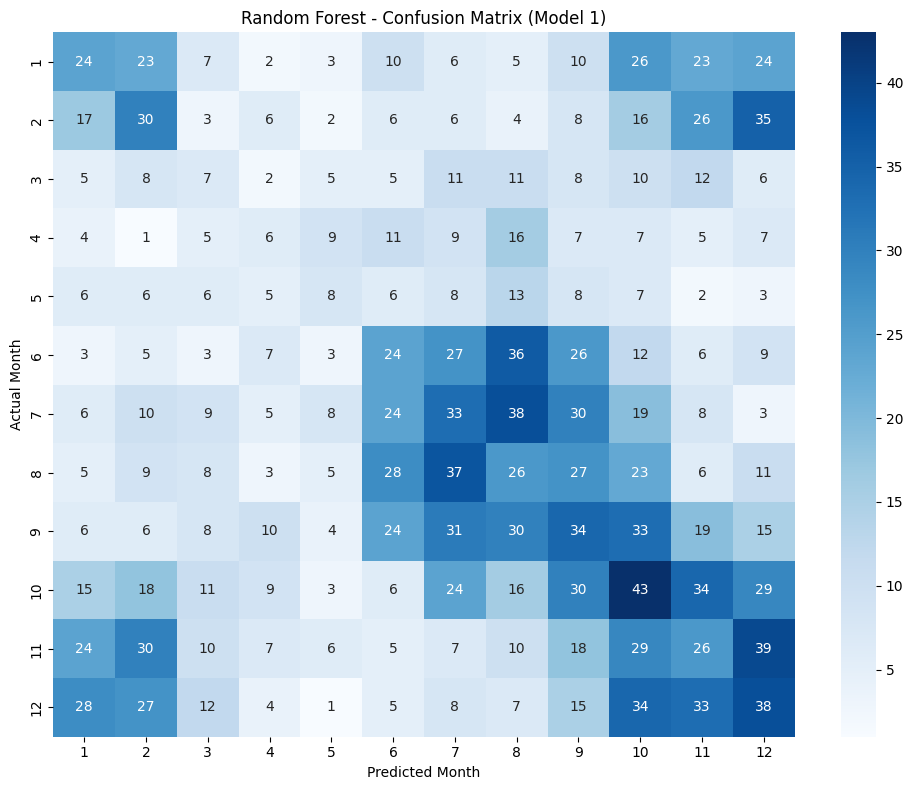

In [22]:
# Cell 6: Train Random Forest for Model 1
print("\n" + "="*60)
print("1. RANDOM FOREST - Model 1")
print("="*60)

# Train
rf_model1 = RandomForestClassifier(
    n_estimators=500,           # More trees
    max_depth=25,               # Deeper trees
    min_samples_split=2,        # Allow finer splits
    min_samples_leaf=1,         # Smaller leaves
    max_features='sqrt',        # Feature sampling
    random_state=RANDOM_STATE, 
    n_jobs=-1
)
rf_model1.fit(X1_train, y1_train)

# Predict
y1_pred_rf = rf_model1.predict(X1_test)

# Evaluate
rf_acc1 = accuracy_score(y1_test, y1_pred_rf)
print(f"\n✓ Random Forest Accuracy: {rf_acc1*100:.2f}%\n")

# Classification Report
print("Classification Report:")
print(classification_report(y1_test, y1_pred_rf, zero_division=0))

# Confusion Matrix
cm_rf1 = confusion_matrix(y1_test, y1_pred_rf)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_rf1, annot=True, fmt='d', cmap='Blues', 
            xticklabels=range(1,13), yticklabels=range(1,13))
plt.title('Random Forest - Confusion Matrix (Model 1)')
plt.xlabel('Predicted Month')
plt.ylabel('Actual Month')
plt.tight_layout()
plt.show()



2. DECISION TREE - Model 1

✓ Decision Tree Accuracy: 14.95%

Classification Report:
              precision    recall  f1-score   support

           1       0.16      0.30      0.21       163
           2       0.15      0.23      0.18       159
           3       0.08      0.11      0.09        90
           4       0.11      0.11      0.11        87
           5       0.11      0.12      0.11        78
           6       0.15      0.16      0.15       161
           7       0.20      0.22      0.21       193
           8       0.11      0.10      0.10       188
           9       0.15      0.11      0.13       220
          10       0.20      0.16      0.18       238
          11       0.09      0.06      0.07       211
          12       0.20      0.11      0.14       212

    accuracy                           0.15      2000
   macro avg       0.14      0.15      0.14      2000
weighted avg       0.15      0.15      0.15      2000



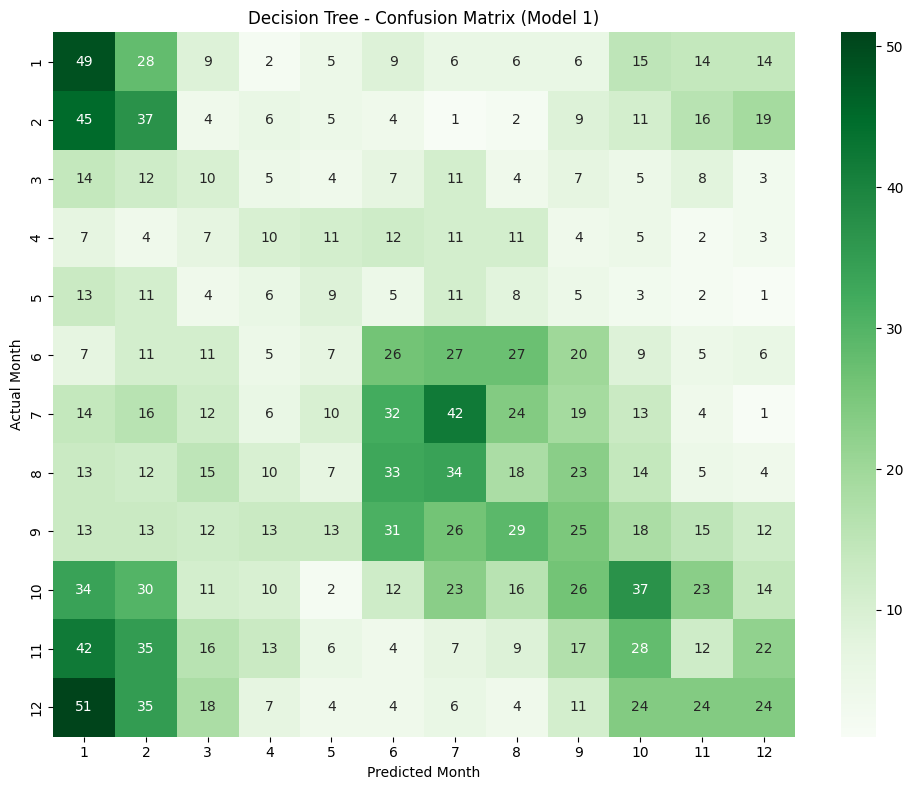

In [23]:
# Cell 7: Train Decision Tree for Model 1
print("\n" + "="*60)
print("2. DECISION TREE - Model 1")
print("="*60)

# Train
dt_model1 = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=20)
dt_model1.fit(X1_train, y1_train)

# Predict
y1_pred_dt = dt_model1.predict(X1_test)

# Evaluate
dt_acc1 = accuracy_score(y1_test, y1_pred_dt)
print(f"\n✓ Decision Tree Accuracy: {dt_acc1*100:.2f}%\n")

# Classification Report
print("Classification Report:")
print(classification_report(y1_test, y1_pred_dt, zero_division=0))

# Confusion Matrix
cm_dt1 = confusion_matrix(y1_test, y1_pred_dt)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_dt1, annot=True, fmt='d', cmap='Greens',
            xticklabels=range(1,13), yticklabels=range(1,13))
plt.title('Decision Tree - Confusion Matrix (Model 1)')
plt.xlabel('Predicted Month')
plt.ylabel('Actual Month')
plt.tight_layout()
plt.show()



3. LOGISTIC REGRESSION - Model 1

✓ Logistic Regression Accuracy: 13.00%

Classification Report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00       163
           2       0.00      0.00      0.00       159
           3       0.00      0.00      0.00        90
           4       0.00      0.00      0.00        87
           5       0.00      0.00      0.00        78
           6       0.00      0.00      0.00       161
           7       0.00      0.00      0.00       193
           8       0.00      0.00      0.00       188
           9       0.17      0.13      0.15       220
          10       0.13      0.73      0.22       238
          11       0.11      0.28      0.16       211
          12       0.00      0.00      0.00       212

    accuracy                           0.13      2000
   macro avg       0.03      0.09      0.04      2000
weighted avg       0.05      0.13      0.06      2000



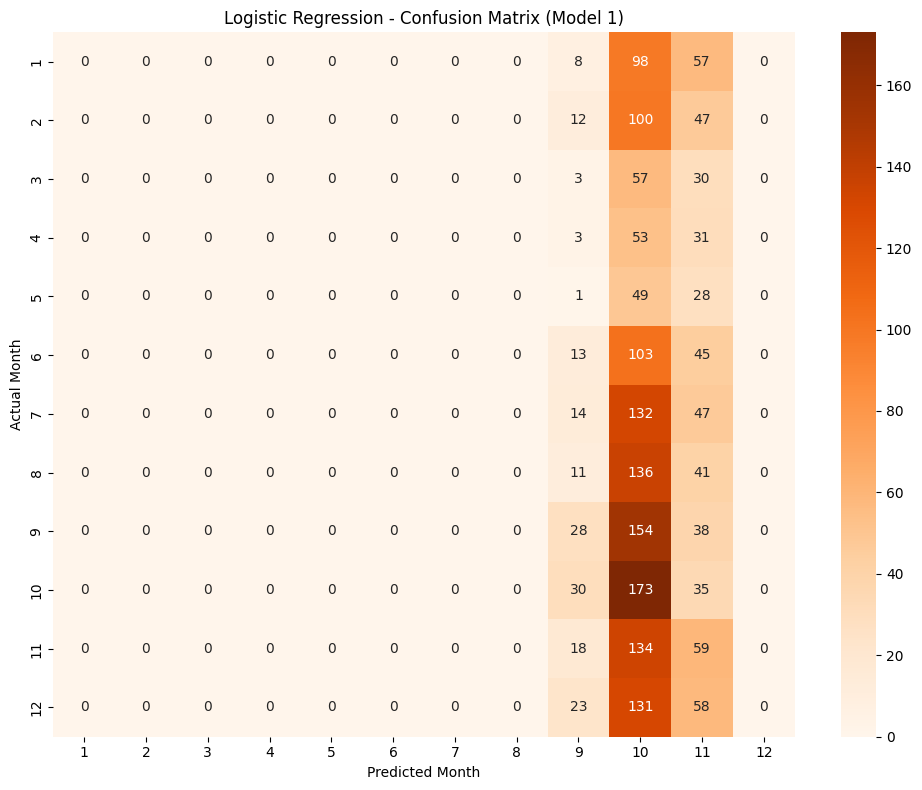

In [24]:
# Cell 8: Train Logistic Regression for Model 1
print("\n" + "="*60)
print("3. LOGISTIC REGRESSION - Model 1")
print("="*60)

# Train
lr_model1 = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, multi_class='multinomial')
lr_model1.fit(X1_train, y1_train)

# Predict
y1_pred_lr = lr_model1.predict(X1_test)

# Evaluate
lr_acc1 = accuracy_score(y1_test, y1_pred_lr)
print(f"\n✓ Logistic Regression Accuracy: {lr_acc1*100:.2f}%\n")

# Classification Report
print("Classification Report:")
print(classification_report(y1_test, y1_pred_lr, zero_division=0))

# Confusion Matrix
cm_lr1 = confusion_matrix(y1_test, y1_pred_lr)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_lr1, annot=True, fmt='d', cmap='Oranges',
            xticklabels=range(1,13), yticklabels=range(1,13))
plt.title('Logistic Regression - Confusion Matrix (Model 1)')
plt.xlabel('Predicted Month')
plt.ylabel('Actual Month')
plt.tight_layout()
plt.show()



MODEL 1 COMPARISON (Crop → Month Prediction)


,Algorithm,Accuracy,Accuracy %
0,Random Forest,0.1495,14.95%
1,Decision Tree,0.1495,14.95%
2,Logistic Regression,0.1300,13.00%


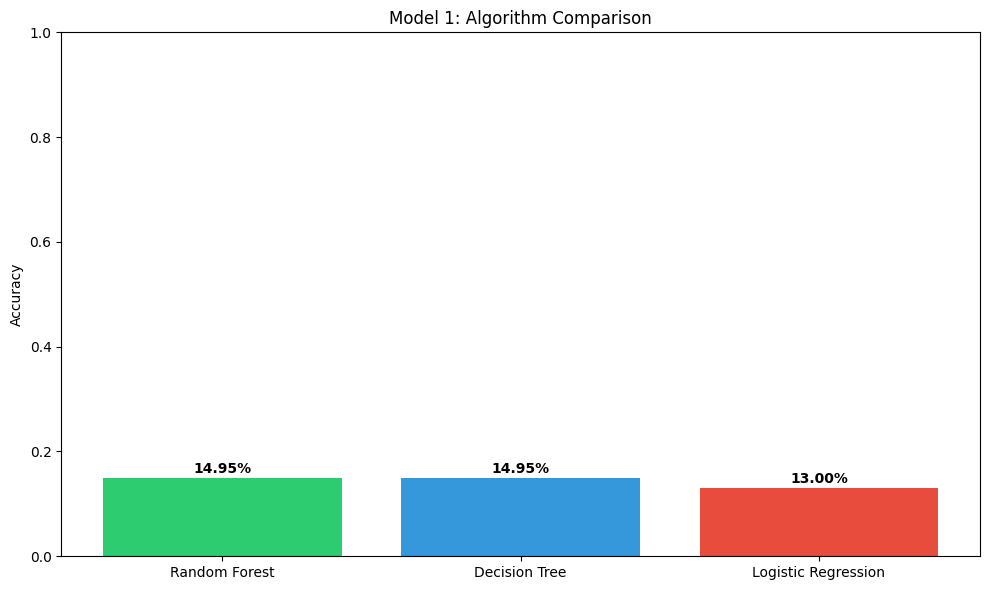


🏆 Best Model for Model 1: Random Forest (14.95%)


In [25]:
# Cell 9: Compare Model 1 Results
print("\n" + "="*80)
print("MODEL 1 COMPARISON (Crop → Month Prediction)")
print("="*80)

model1_results = pd.DataFrame({
    'Algorithm': ['Random Forest', 'Decision Tree', 'Logistic Regression'],
    'Accuracy': [rf_acc1, dt_acc1, lr_acc1],
    'Accuracy %': [f"{rf_acc1*100:.2f}%", f"{dt_acc1*100:.2f}%", f"{lr_acc1*100:.2f}%"]
})

model1_results = model1_results.sort_values('Accuracy', ascending=False).reset_index(drop=True)
display(model1_results)

# Visualization
plt.figure(figsize=(10, 6))
plt.bar(model1_results['Algorithm'], model1_results['Accuracy'], 
        color=['#2ecc71', '#3498db', '#e74c3c'])
plt.ylabel('Accuracy')
plt.title('Model 1: Algorithm Comparison')
plt.ylim([0, 1])
for i, v in enumerate(model1_results['Accuracy']):
    plt.text(i, v + 0.01, f'{v*100:.2f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

best_model1_name = model1_results.iloc[0]['Algorithm']
best_model1_acc = model1_results.iloc[0]['Accuracy']
print(f"\n🏆 Best Model for Model 1: {best_model1_name} ({best_model1_acc*100:.2f}%)")

In [26]:
# Cell 10: Prepare Data for Model 2 (Predict Crop from Month, State, City)
print("\n" + "="*80)
print("MODEL 2: Predict Best Crop (Given: Month, State, City)")
print("="*80)

# Features: month, state, city
X2 = pd.DataFrame({
    "month": df['best_month'],
    "state": encoders['state'].transform(df['state']),
    "city": encoders['city'].transform(df['city'])
})

# Target: crop (encoded)
y2 = encoders['crop_label'].transform(df['crop'])

# Train/test split
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=RANDOM_STATE, stratify=y2
)

print(f"Training samples: {len(X2_train)}")
print(f"Testing samples: {len(X2_test)}")
print(f"Number of classes (crops): {df['crop'].nunique()}")



MODEL 2: Predict Best Crop (Given: Month, State, City)
Training samples: 8000
Testing samples: 2000
Number of classes (crops): 20



1. RANDOM FOREST - Model 2

✓ Random Forest Accuracy: 9.25%

Classification Report:
              precision    recall  f1-score   support

      Banana       0.01      0.01      0.01       103
      Barley       0.10      0.10      0.10        99
      Chilli       0.13      0.16      0.14       105
     Coconut       0.05      0.03      0.04        97
      Coffee       0.08      0.06      0.07       101
      Cotton       0.11      0.11      0.11        89
   Groundnut       0.11      0.12      0.12        99
       Maize       0.12      0.12      0.12       104
     Millets       0.08      0.08      0.08        96
     Mustard       0.08      0.10      0.09        94
       Onion       0.08      0.10      0.09        94
      Potato       0.08      0.08      0.08       108
      Pulses       0.10      0.11      0.10       100
        Rice       0.06      0.08      0.07       101
      Rubber       0.16      0.17      0.17       107
     Soybean       0.11      0.12      0.12       

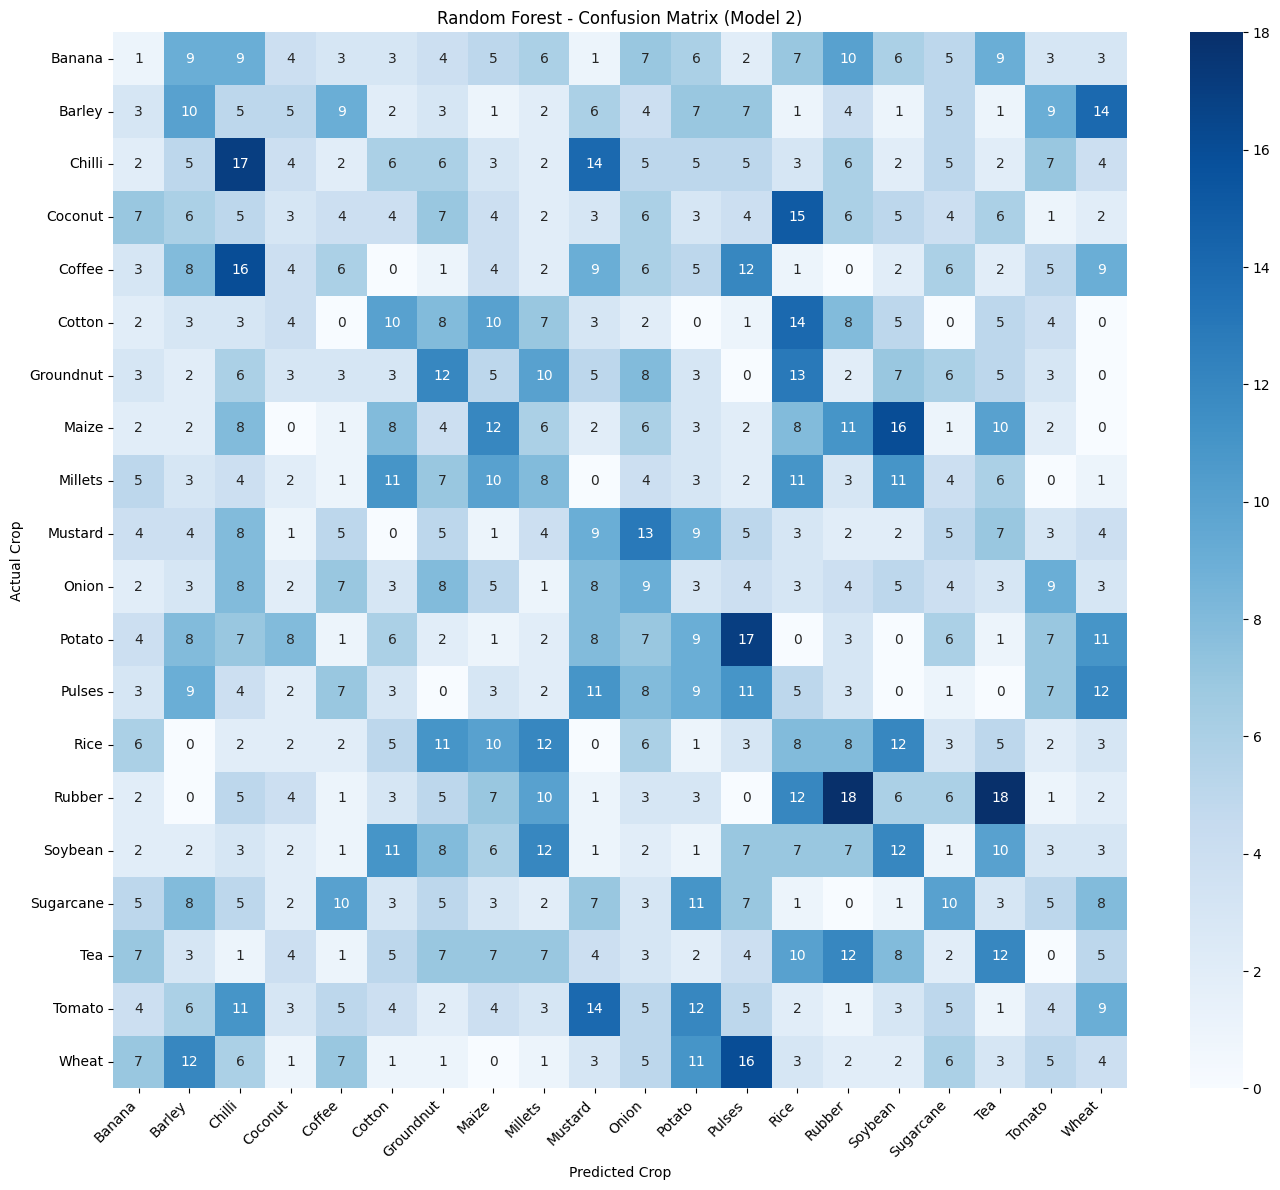

In [27]:
# Cell 11: Train Random Forest for Model 2
print("\n" + "="*60)
print("1. RANDOM FOREST - Model 2")
print("="*60)

# Train
rf_model2 = RandomForestClassifier(
    n_estimators=500,           # More trees
    max_depth=25,               # Deeper trees
    min_samples_split=2,        # Allow finer splits
    min_samples_leaf=1,         # Smaller leaves
    max_features='sqrt',        # Feature sampling
    random_state=RANDOM_STATE, 
    n_jobs=-1
)
rf_model2.fit(X2_train, y2_train)

# Predict
y2_pred_rf = rf_model2.predict(X2_test)

# Evaluate
rf_acc2 = accuracy_score(y2_test, y2_pred_rf)
print(f"\n✓ Random Forest Accuracy: {rf_acc2*100:.2f}%\n")

# Classification Report
print("Classification Report:")
print(classification_report(y2_test, y2_pred_rf, 
                           target_names=encoders['crop_label'].classes_, 
                           zero_division=0))

# Confusion Matrix
cm_rf2 = confusion_matrix(y2_test, y2_pred_rf)
plt.figure(figsize=(14, 12))
sns.heatmap(cm_rf2, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoders['crop_label'].classes_,
            yticklabels=encoders['crop_label'].classes_)
plt.title('Random Forest - Confusion Matrix (Model 2)')
plt.xlabel('Predicted Crop')
plt.ylabel('Actual Crop')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



2. DECISION TREE - Model 2

✓ Decision Tree Accuracy: 8.55%

Classification Report:
              precision    recall  f1-score   support

      Banana       0.03      0.07      0.05       103
      Barley       0.07      0.13      0.09        99
      Chilli       0.10      0.20      0.14       105
     Coconut       0.07      0.06      0.06        97
      Coffee       0.07      0.07      0.07       101
      Cotton       0.08      0.12      0.10        89
   Groundnut       0.10      0.13      0.11        99
       Maize       0.12      0.13      0.13       104
     Millets       0.05      0.05      0.05        96
     Mustard       0.11      0.11      0.11        94
       Onion       0.05      0.04      0.05        94
      Potato       0.15      0.10      0.12       108
      Pulses       0.09      0.06      0.07       100
        Rice       0.08      0.07      0.07       101
      Rubber       0.19      0.13      0.16       107
     Soybean       0.12      0.08      0.10       

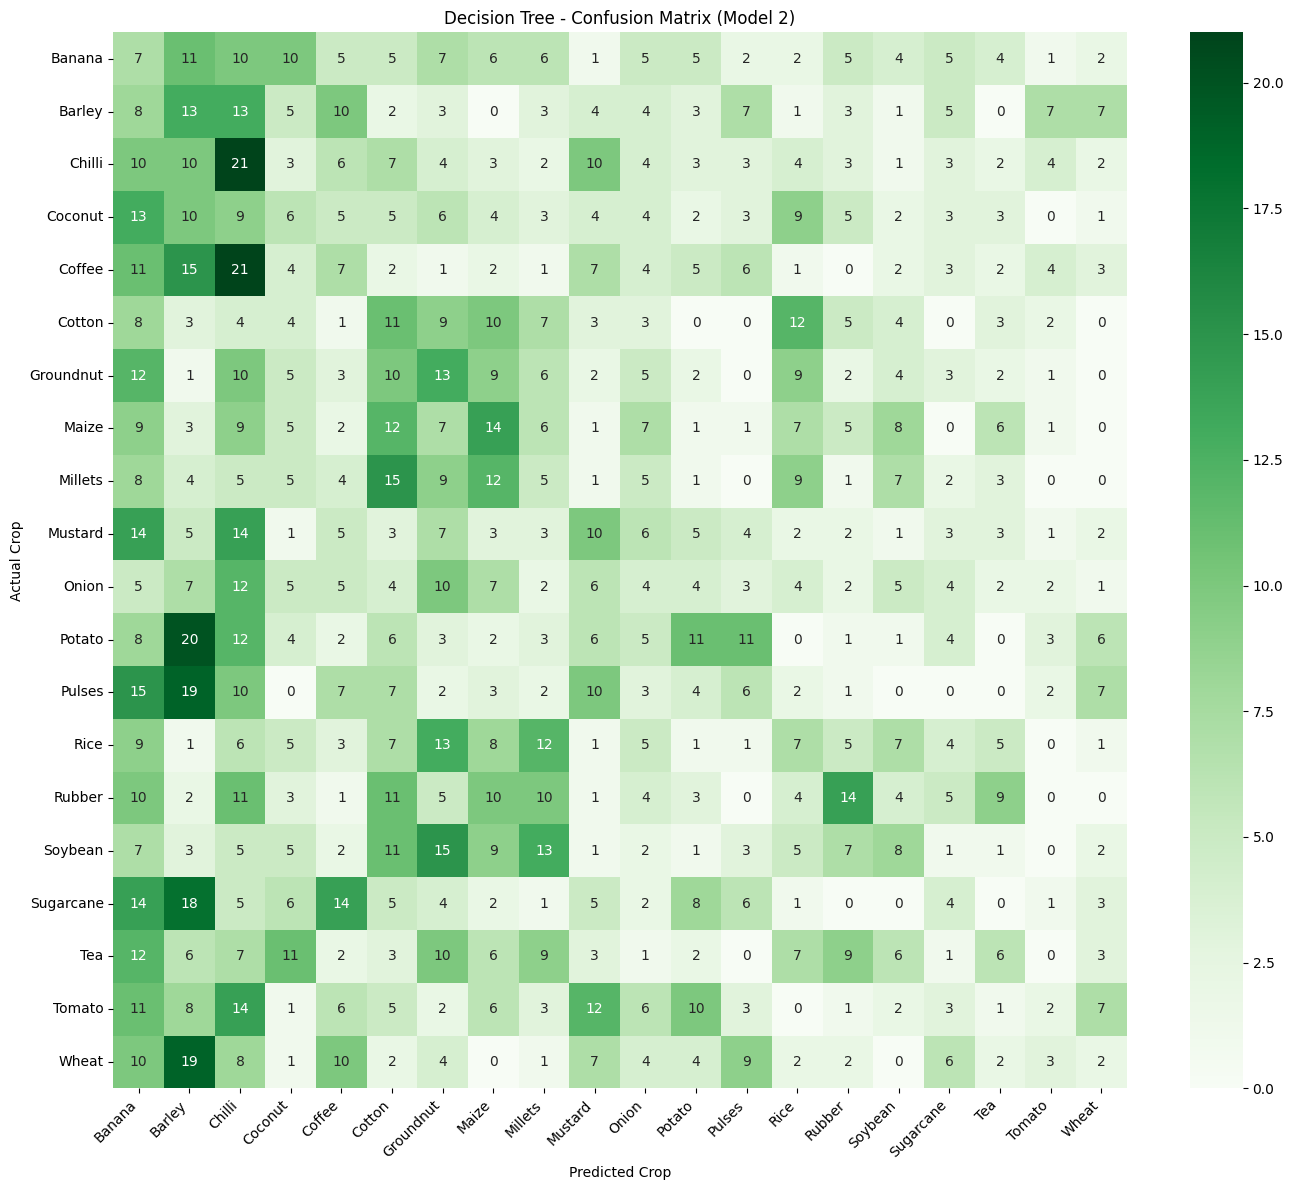

In [28]:
# Cell 12: Train Decision Tree for Model 2
print("\n" + "="*60)
print("2. DECISION TREE - Model 2")
print("="*60)

# Train
dt_model2 = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=20)
dt_model2.fit(X2_train, y2_train)

# Predict
y2_pred_dt = dt_model2.predict(X2_test)

# Evaluate
dt_acc2 = accuracy_score(y2_test, y2_pred_dt)
print(f"\n✓ Decision Tree Accuracy: {dt_acc2*100:.2f}%\n")

# Classification Report
print("Classification Report:")
print(classification_report(y2_test, y2_pred_dt,
                           target_names=encoders['crop_label'].classes_,
                           zero_division=0))

# Confusion Matrix
cm_dt2 = confusion_matrix(y2_test, y2_pred_dt)
plt.figure(figsize=(14, 12))
sns.heatmap(cm_dt2, annot=True, fmt='d', cmap='Greens',
            xticklabels=encoders['crop_label'].classes_,
            yticklabels=encoders['crop_label'].classes_)
plt.title('Decision Tree - Confusion Matrix (Model 2)')
plt.xlabel('Predicted Crop')
plt.ylabel('Actual Crop')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



3. LOGISTIC REGRESSION - Model 2

✓ Logistic Regression Accuracy: 9.05%

Classification Report:
              precision    recall  f1-score   support

      Banana       0.00      0.00      0.00       103
      Barley       0.00      0.00      0.00        99
      Chilli       0.11      0.57      0.18       105
     Coconut       0.00      0.00      0.00        97
      Coffee       0.00      0.00      0.00       101
      Cotton       0.13      0.06      0.08        89
   Groundnut       0.00      0.00      0.00        99
       Maize       0.12      0.17      0.14       104
     Millets       0.08      0.08      0.08        96
     Mustard       0.09      0.23      0.13        94
       Onion       0.00      0.00      0.00        94
      Potato       0.02      0.02      0.02       108
      Pulses       0.06      0.02      0.03       100
        Rice       0.00      0.00      0.00       101
      Rubber       0.14      0.24      0.17       107
     Soybean       0.00      0.00     

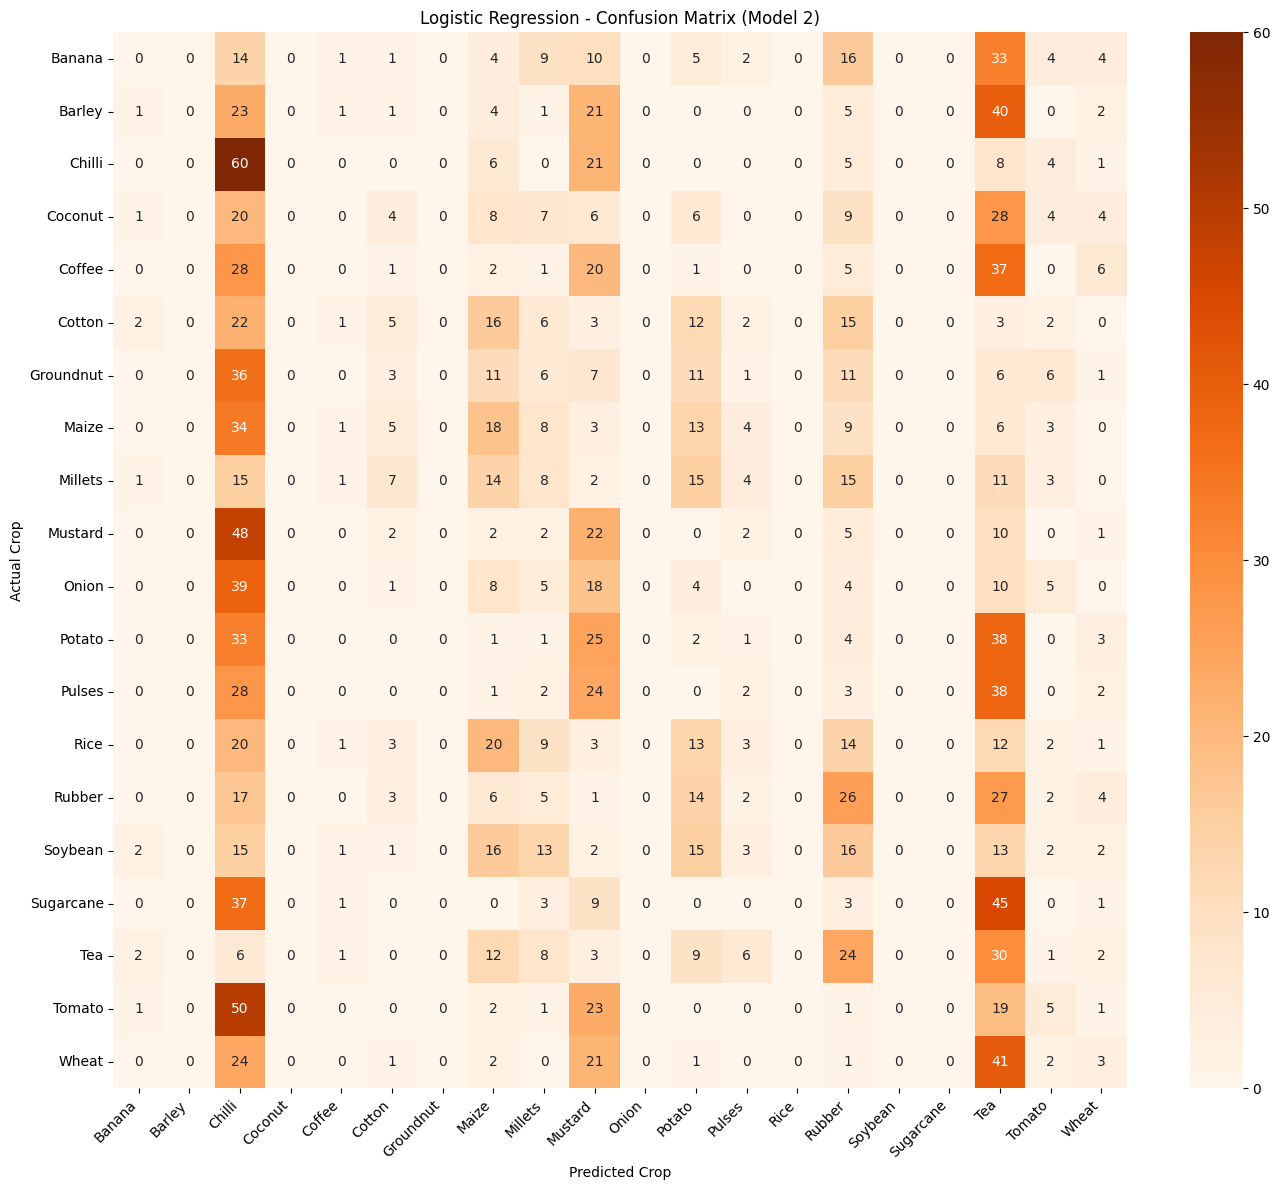

In [29]:
# Cell 13: Train Logistic Regression for Model 2
print("\n" + "="*60)
print("3. LOGISTIC REGRESSION - Model 2")
print("="*60)

# Train
lr_model2 = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, multi_class='multinomial')
lr_model2.fit(X2_train, y2_train)

# Predict
y2_pred_lr = lr_model2.predict(X2_test)

# Evaluate
lr_acc2 = accuracy_score(y2_test, y2_pred_lr)
print(f"\n✓ Logistic Regression Accuracy: {lr_acc2*100:.2f}%\n")

# Classification Report
print("Classification Report:")
print(classification_report(y2_test, y2_pred_lr,
                           target_names=encoders['crop_label'].classes_,
                           zero_division=0))

# Confusion Matrix
cm_lr2 = confusion_matrix(y2_test, y2_pred_lr)
plt.figure(figsize=(14, 12))
sns.heatmap(cm_lr2, annot=True, fmt='d', cmap='Oranges',
            xticklabels=encoders['crop_label'].classes_,
            yticklabels=encoders['crop_label'].classes_)
plt.title('Logistic Regression - Confusion Matrix (Model 2)')
plt.xlabel('Predicted Crop')
plt.ylabel('Actual Crop')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()




MODEL 2 COMPARISON (Month → Crop Prediction)


,Algorithm,Accuracy,Accuracy %
0,Random Forest,0.0925,9.25%
1,Logistic Regression,0.0905,9.05%
2,Decision Tree,0.0855,8.55%


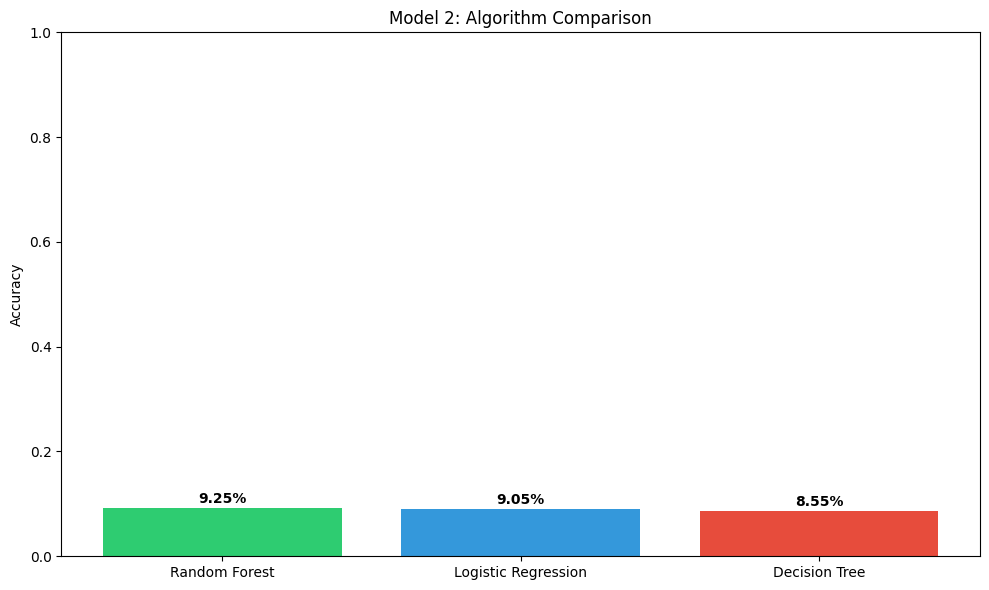


🏆 Best Model for Model 2: Random Forest (9.25%)


In [30]:
# Cell 14: Compare Model 2 Results
print("\n" + "="*80)
print("MODEL 2 COMPARISON (Month → Crop Prediction)")
print("="*80)

model2_results = pd.DataFrame({
    'Algorithm': ['Random Forest', 'Decision Tree', 'Logistic Regression'],
    'Accuracy': [rf_acc2, dt_acc2, lr_acc2],
    'Accuracy %': [f"{rf_acc2*100:.2f}%", f"{dt_acc2*100:.2f}%", f"{lr_acc2*100:.2f}%"]
})

model2_results = model2_results.sort_values('Accuracy', ascending=False).reset_index(drop=True)
display(model2_results)

# Visualization
plt.figure(figsize=(10, 6))
plt.bar(model2_results['Algorithm'], model2_results['Accuracy'],
        color=['#2ecc71', '#3498db', '#e74c3c'])
plt.ylabel('Accuracy')
plt.title('Model 2: Algorithm Comparison')
plt.ylim([0, 1])
for i, v in enumerate(model2_results['Accuracy']):
    plt.text(i, v + 0.01, f'{v*100:.2f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

best_model2_name = model2_results.iloc[0]['Algorithm']
best_model2_acc = model2_results.iloc[0]['Accuracy']
print(f"\n🏆 Best Model for Model 2: {best_model2_name} ({best_model2_acc*100:.2f}%)")


In [31]:
# Cell 15: Overall Summary and Save Best Models
print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

# Create summary table
summary = pd.DataFrame({
    'Task': ['Model 1: Crop → Month', 'Model 2: Month → Crop'],
    'Best Algorithm': [best_model1_name, best_model2_name],
    'Accuracy': [f"{best_model1_acc*100:.2f}%", f"{best_model2_acc*100:.2f}%"]
})

display(summary)

# Determine which models to save
if best_model1_name == 'Random Forest':
    final_model1 = rf_model1
elif best_model1_name == 'Decision Tree':
    final_model1 = dt_model1
else:
    final_model1 = lr_model1

if best_model2_name == 'Random Forest':
    final_model2 = rf_model2
elif best_model2_name == 'Decision Tree':
    final_model2 = dt_model2
else:
    final_model2 = lr_model2

# Save best models
joblib.dump(final_model1, "crop_month_model.pkl")
joblib.dump(final_model2, "month_crop_model.pkl")
joblib.dump(encoders, "encoders.pkl")

print("\n✓ Saved best models:")
print(f"  - crop_month_model.pkl ({best_model1_name})")
print(f"  - month_crop_model.pkl ({best_model2_name})")
print("  - encoders.pkl")



FINAL SUMMARY


,Task,Best Algorithm,Accuracy
0,Model 1: Crop → Month,Random Forest,14.95%
1,Model 2: Month → Crop,Random Forest,9.25%



✓ Saved best models:
  - crop_month_model.pkl (Random Forest)
  - month_crop_model.pkl (Random Forest)
  - encoders.pkl


In [32]:
# Cell 16: Save Results to CSV
# Save comparison results
results_summary = pd.DataFrame({
    'Model': ['Model 1 - Random Forest', 'Model 1 - Decision Tree', 'Model 1 - Logistic Regression',
              'Model 2 - Random Forest', 'Model 2 - Decision Tree', 'Model 2 - Logistic Regression'],
    'Task': ['Crop → Month', 'Crop → Month', 'Crop → Month',
             'Month → Crop', 'Month → Crop', 'Month → Crop'],
    'Accuracy': [rf_acc1, dt_acc1, lr_acc1, rf_acc2, dt_acc2, lr_acc2],
    'Accuracy %': [f"{rf_acc1*100:.2f}%", f"{dt_acc1*100:.2f}%", f"{lr_acc1*100:.2f}%",
                   f"{rf_acc2*100:.2f}%", f"{dt_acc2*100:.2f}%", f"{lr_acc2*100:.2f}%"]
})

results_summary.to_csv('model_comparison_results.csv', index=False)
print("\n✓ Results saved to: model_comparison_results.csv")
display(results_summary)

print("\n" + "="*80)
print("✓ Training and Evaluation Complete!")
print("="*80)



✓ Results saved to: model_comparison_results.csv


,Model,Task,Accuracy,Accuracy %
0,Model 1 - Random Forest,Crop → Month,0.1495,14.95%
1,Model 1 - Decision Tree,Crop → Month,0.1495,14.95%
2,Model 1 - Logistic Regression,Crop → Month,0.1300,13.00%
3,Model 2 - Random Forest,Month → Crop,0.0925,9.25%
4,Model 2 - Decision Tree,Month → Crop,0.0855,8.55%
5,Model 2 - Logistic Regression,Month → Crop,0.0905,9.05%



✓ Training and Evaluation Complete!
